In [1]:
import pandas as pd

In [7]:
df = pd.read_csv("detectability_results.csv")
df

,protein_id,label,length,tryptic_peptide_density,hla_sb_count,hla_sb_density
0,NEO_ENSG00000264589__TCONS_00371165__ncRNA__10...,neogene,19,0.157895,5.0,0.263158
1,NEO_Ew_NG49.1_739_987,neogene,83,0.301205,112.0,1.349398
2,NEO_Ew_NG11.5_130_312,neogene,61,0.180328,6.0,0.098361
3,NEO_TCONS_00093252_307_423,neogene,39,0.051282,38.0,0.974359
4,NEO_Ew_NG11.9_229_285,neogene,19,0.210526,35.0,1.842105
...,...,...,...,...,...,...
723,CAN_sp_Q5VTE0_EF1A3_HUMAN,canonical,462,0.183983,281.0,0.608225
724,CAN_sp_O94864-2_ST65G_HUMAN,canonical,412,0.087379,290.0,0.703883
725,CAN_sp_Q8IUZ0_LRC49_HUMAN,canonical,686,0.202624,478.0,0.696793
726,CAN_sp_Q86X10-3_RLGPB_HUMAN,canonical,1491,0.130785,1211.0,0.812207


In [8]:
df = df.dropna()

In [9]:
df["tryptic_peptide_count"] = (df["tryptic_peptide_density"] * df["length"]).round().astype(int)
df["hla_to_tryptic_ratio"] = df["hla_sb_count"] / df["tryptic_peptide_count"]

C:\Users\Masha\AppData\Local\Temp\ipykernel_19400\3914722051.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["tryptic_peptide_count"] = (df["tryptic_peptide_density"] * df["length"]).round().astype(int)
C:\Users\Masha\AppData\Local\Temp\ipykernel_19400\3914722051.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["hla_to_tryptic_ratio"] = df["hla_sb_count"] / df["tryptic_peptide_count"]


In [28]:
detected_in_tryptic = ['NEO_Ew_NG3.4_97_360', 'NEO_TCONS_00842344_338_622', 'NEO_Ew_NG49.1_1033_1521']
detected_in_ip = ['NEO_Ew_NG48.13_484_558',
'NEO_ENSG00000232783_ENSG00000213113__Ew_NG3.5__ncRNA__2__ATG',
'NEO_Ew_NG3.4_97_360',
'NEO_ENSG00000236894_ENSG00000279212__Ew_NG11.4__ncRNA__29__ATC',
'NEO_ENSG00000253888__Ew_NG42.5__ncRNA__9__ATG',
'NEO_Ew_NG44.2_655_837',
'NEO_TCONS_00108764_183_341',
'NEO_TCONS_00112834_185_397',
'NEO_TCONS_00808337_14985_15092',
'NEO_TCONS_00092839_5239_5376',
'NEO_ENSG00000251460_XLOC_075126__TCONS_00632959__ncRNA__31__ATG'
]

In [10]:
ng = df[df['label']=='neogene']

In [11]:
can = df[df['label']=='canonical'].sample(n=len(ng), random_state=42)

In [12]:
ng.describe()

,length,tryptic_peptide_density,hla_sb_count,hla_sb_density,tryptic_peptide_count,hla_to_tryptic_ratio
count,347.000000,347.000000,347.00000,347.000000,347.000000,347.000000
mean,43.308357,0.178974,24.51585,0.499504,7.798271,inf
std,35.696214,0.095228,26.49750,0.365852,8.610029,NaN
min,8.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,20.000000,0.100000,6.00000,0.228220,2.000000,1.162281
50%,35.000000,0.179487,15.00000,0.441176,5.000000,2.375000
75%,54.000000,0.252660,34.00000,0.700000,10.500000,5.449495
max,335.000000,0.431818,131.00000,1.931818,75.000000,inf


In [13]:
can.describe()

,length,tryptic_peptide_density,hla_sb_count,hla_sb_density,tryptic_peptide_count,hla_to_tryptic_ratio
count,347.000000,347.000000,347.000000,347.000000,347.000000,347.000000
mean,554.855908,0.167435,386.095101,0.708415,87.048991,inf
std,647.820005,0.067409,382.403314,0.185776,86.709071,NaN
min,64.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,224.000000,0.122029,148.000000,0.618841,34.000000,3.192478
50%,395.000000,0.165323,296.000000,0.713846,60.000000,4.309859
75%,657.000000,0.208514,479.000000,0.839359,115.000000,6.099858
max,8384.000000,0.386207,3381.000000,1.155556,805.000000,inf


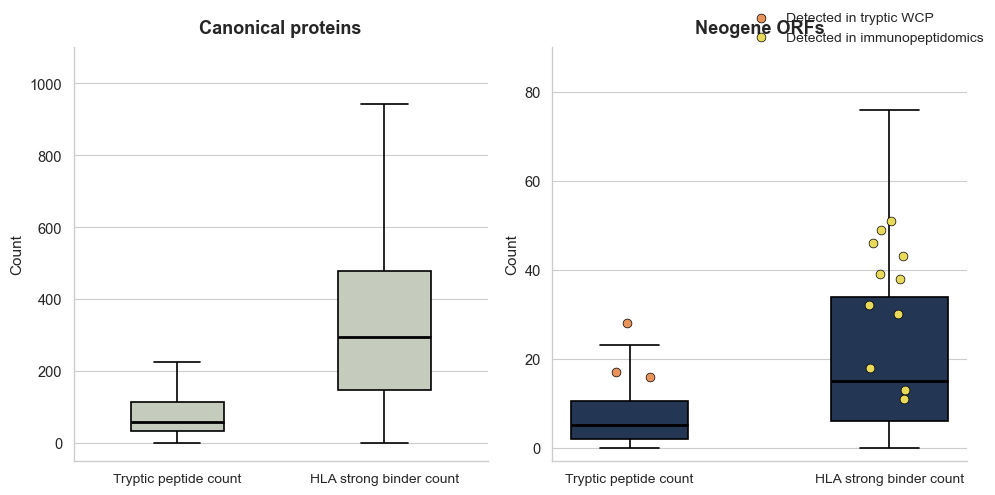

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sns.set_style("whitegrid")
sns.set_context("paper", font_scale=1.2)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

colors = {
    "canonical":        "#C5CEBB",
    "neogene":          "#1b365d",
    "detected_tryptic": "#E8935A",  # warm amber
    "detected_ip":      "#E8D95A",  # warm pink
}

def prep(df, label):
    return pd.DataFrame({
        "value":      pd.concat([df["tryptic_peptide_count"], df["hla_sb_count"]], ignore_index=True),
        "metric":     ["Tryptic peptide count"] * len(df) + ["HLA strong binder count"] * len(df),
        "protein_id": pd.concat([df["protein_id"], df["protein_id"]], ignore_index=True),
    })

panels = [
    (prep(can, "canonical"), "Canonical proteins", colors["canonical"]),
    (prep(ng,  "neogene"),   "Neogene ORFs",       colors["neogene"]),
]

highlight_lists = {
    "Tryptic peptide count":   detected_in_tryptic,
    "HLA strong binder count": detected_in_ip,
}

highlight_colors = {
    "Tryptic peptide count":   colors["detected_tryptic"],
    "HLA strong binder count": colors["detected_ip"],
}

for ax, (df_long, title, color) in zip(axes, panels):

    sns.boxplot(
        data=df_long, x="metric", y="value",
        color=color, width=0.45,
        fliersize=0, linewidth=1.2,
        medianprops=dict(color="black", linewidth=2),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black"),
        boxprops=dict(edgecolor="black"),
        ax=ax,
    )

    # highlighted dots on neogene panel only
    if title == "Neogene ORFs":
        for i, metric in enumerate(["Tryptic peptide count", "HLA strong binder count"]):
            det_ids = highlight_lists[metric]
            col = "tryptic_peptide_count" if metric == "Tryptic peptide count" else "hla_sb_count"
            vals = ng.loc[ng["protein_id"].isin(det_ids), col].dropna()
            jitter = np.random.uniform(-0.08, 0.08, size=len(vals))
            ax.scatter(i + jitter, vals,
               color=highlight_colors[metric], s=40, zorder=5,
               edgecolors="black", linewidths=0.5)
        ax.set_ylim(-3, 90)

    if title == "Canonical proteins":
        ax.set_ylim(-50, 1100)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("Count", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=10)

fig.legend(
    handles=[
        plt.scatter([], [], color=colors["detected_tryptic"], edgecolors="black",
                    linewidths=0.5, s=40, label="Detected in tryptic WCP"),
        plt.scatter([], [], color=colors["detected_ip"], edgecolors="black",
                    linewidths=0.5, s=40, label="Detected in immunopeptidomics"),
    ],
    loc="upper right", frameon=False, fontsize=10
)

plt.tight_layout()
plt.savefig("detectability_boxplot.pdf", bbox_inches="tight", dpi=300)
plt.show()

In [ ]:
"#E8D95A"